In [2]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import requests
import zipfile

extract_dir = "extracted_files"
zip_path = "dataset.zip"

if not os.path.exists(extract_dir):
    url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/EFOEudjvmSIMYp700qwtrg/dataset.zip'

    # Stream the download straight to disk so it doesn't fill your RAM
    with requests.get(url, stream=True) as r:
        total = int(r.headers.get('content-length', 0))
        print(f"Download size: {total / 1e9:.2f} GB")
        with open(zip_path, 'wb') as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    os.remove(zip_path)  # free up the space used by the ZIP

print("Extracted files:", os.listdir(extract_dir))

TRAIN_DATASET_PATH = 'extracted_files/dataset/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/'

Extracted files: ['dataset']


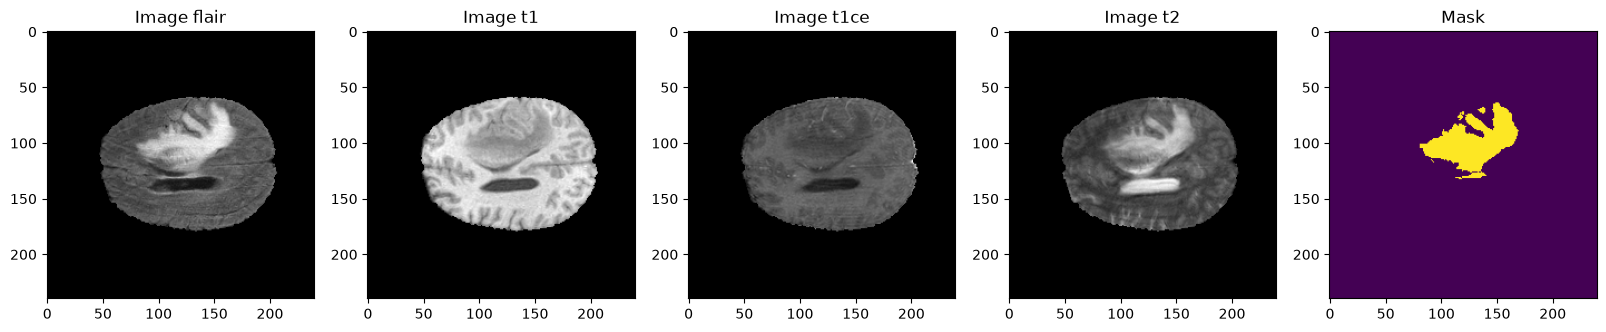

In [3]:
patient = 'BraTS20_Training_001'
folder = TRAIN_DATASET_PATH + patient + '/'

flair = nib.load(folder + patient + '_flair.nii').get_fdata()
t1    = nib.load(folder + patient + '_t1.nii').get_fdata()
t1ce  = nib.load(folder + patient + '_t1ce.nii').get_fdata()
t2    = nib.load(folder + patient + '_t2.nii').get_fdata()
mask  = nib.load(folder + patient + '_seg.nii').get_fdata()

slice_w = 25
s = flair.shape[0] // 2 - slice_w   # which slice to display

fig, axes = plt.subplots(1, 5, figsize=(20, 10))
for ax, img, title in zip(axes, [flair, t1, t1ce, t2, mask],
                          ['Image flair', 'Image t1', 'Image t1ce', 'Image t2', 'Mask']):
    ax.imshow(img[:, :, s], cmap='gray' if title != 'Mask' else None)
    ax.set_title(title)
plt.show()

In [4]:
import torch
import torch.nn as nn


def double_convolution(in_channels, out_channels):
    # padding=1 keeps the output the same size as the input
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=True)
    )


class UNetBrain(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.max_pool2d = nn.MaxPool2d(kernel_size=2, stride=2)

        # Contracting path
        self.down_convolution_1 = double_convolution(1, 64)
        self.down_convolution_2 = double_convolution(64, 128)
        self.down_convolution_3 = double_convolution(128, 256)
        self.down_convolution_4 = double_convolution(256, 512)
        self.down_convolution_5 = double_convolution(512, 1024)

        # Expanding path
        self.up_transpose_1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.up_convolution_1 = double_convolution(1024, 512)
        self.up_transpose_2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.up_convolution_2 = double_convolution(512, 256)
        self.up_transpose_3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.up_convolution_3 = double_convolution(256, 128)
        self.up_transpose_4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.up_convolution_4 = double_convolution(128, 64)

        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        down_1 = self.down_convolution_1(x)
        down_2 = self.max_pool2d(down_1)
        down_3 = self.down_convolution_2(down_2)
        down_4 = self.max_pool2d(down_3)
        down_5 = self.down_convolution_3(down_4)
        down_6 = self.max_pool2d(down_5)
        down_7 = self.down_convolution_4(down_6)
        down_8 = self.max_pool2d(down_7)
        down_9 = self.down_convolution_5(down_8)

        up_1 = self.up_transpose_1(down_9)
        up_2 = self.up_convolution_1(torch.cat([down_7, up_1], 1))
        up_3 = self.up_transpose_2(up_2)
        up_4 = self.up_convolution_2(torch.cat([down_5, up_3], 1))
        up_5 = self.up_transpose_3(up_4)
        up_6 = self.up_convolution_3(torch.cat([down_3, up_5], 1))
        up_7 = self.up_transpose_4(up_6)
        up_8 = self.up_convolution_4(torch.cat([down_1, up_7], 1))

        return self.out(up_8)

In [5]:
from sklearn.model_selection import train_test_split

# One folder per patient
all_ids = [f.name for f in os.scandir(TRAIN_DATASET_PATH) if f.is_dir()]

train_test_ids, val_ids = train_test_split(all_ids, test_size=0.3, random_state=42)
train_ids, test_ids = train_test_split(train_test_ids, test_size=0.3, random_state=42)

print(f"Train: {len(train_ids)} | Validation: {len(val_ids)} | Test: {len(test_ids)}")


def load_dataset(ids, path):
    images = np.zeros((len(ids) * 10, 240, 240), np.float32)
    masks = np.zeros((len(ids) * 10, 240, 240), np.float32)

    i = 0
    for id in ids:
        t2 = nib.load(f"{path}{id}/{id}_t2.nii").get_fdata()
        seg = nib.load(f"{path}{id}/{id}_seg.nii").get_fdata()

        for s in range(50, seg.shape[2] - 50, 10):   # every 10th slice from the middle
            images[i] = t2[:, :, s] / t2.max()
            masks[i] = seg[:, :, s] > 0               # any tumour type = 1
            i += 1

    images = np.expand_dims(images[:i], axis=1)
    masks = np.expand_dims(masks[:i], axis=1)
    return images, masks


# We only load the validation set. The model is pre-trained, so no training data is needed
val_images, val_masks = load_dataset(val_ids, TRAIN_DATASET_PATH)
print(val_images.shape, val_masks.shape)

Train: 9 | Validation: 6 | Test: 5
(36, 1, 240, 240) (36, 1, 240, 240)


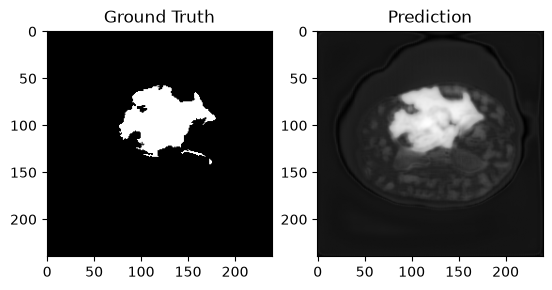

In [6]:
from torch.utils.data import TensorDataset, DataLoader

test_dataset = TensorDataset(torch.from_numpy(val_images).float(), torch.from_numpy(val_masks).float())
test_dataloader = DataLoader(test_dataset, batch_size=8, shuffle=False)

# Download the pre-trained checkpoint
checkpoint_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/HATpl02lA0ykn9aAU9K6sA/checkpoint-epoch-29.pt'
local_checkpoint_path = 'checkpoint-epoch-29.pt'

if not os.path.exists(local_checkpoint_path):
    response = requests.get(checkpoint_url)
    with open(local_checkpoint_path, 'wb') as f:
        f.write(response.content)

checkpoint = torch.load(local_checkpoint_path, map_location=torch.device('cpu'), weights_only=False)

model2 = UNetBrain(num_classes=1)
model2.load_state_dict(checkpoint['model_state_dict'])
model2.eval()

X, y = next(iter(test_dataloader))   # one batch of 8 slices

with torch.inference_mode():
    y_pred = model2(X)

# Compare ground truth and prediction for one slice
i = 3
plt.subplot(121)
plt.imshow(y[i, 0], cmap='gray')
plt.title('Ground Truth')
plt.subplot(122)
plt.imshow(y_pred[i, 0], cmap='gray')
plt.title('Prediction')
plt.show()

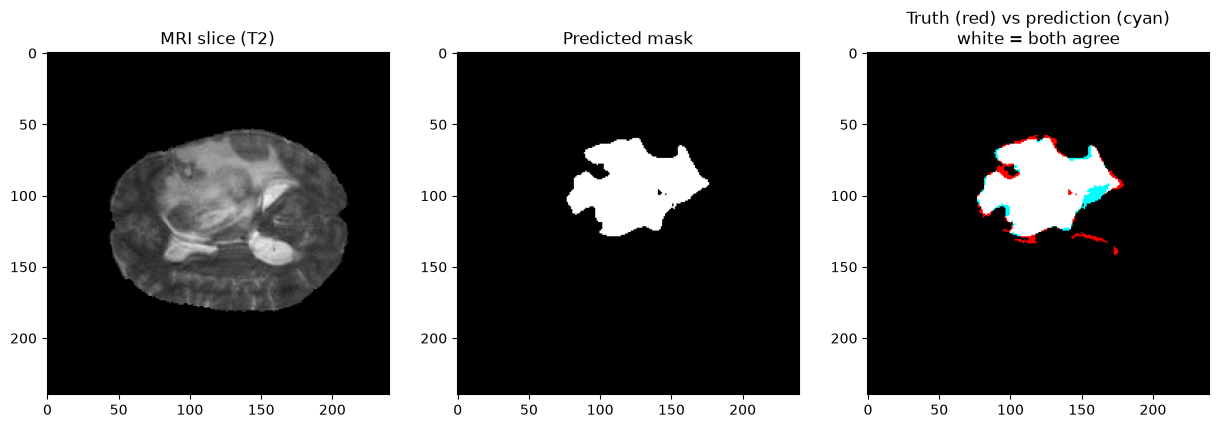

In [7]:
i = 3   # try 0 to 7

# Raw scores -> probability (0 to 1) -> mask (0 or 1)
probs = torch.sigmoid(y_pred[i, 0])
pred_mask = (probs > 0.5).float().numpy()
true_mask = y[i, 0].numpy()
scan = X[i, 0].numpy()

# Colour code: red = missed by model, cyan = correct or false alarm, white = overlap
overlay = np.zeros((*true_mask.shape, 3))
overlay[..., 0] = true_mask   # red channel: real tumour
overlay[..., 1] = pred_mask   # green channel: predicted tumour
overlay[..., 2] = pred_mask   # blue channel: predicted tumour

plt.figure(figsize=(15, 5))
plt.subplot(131)
plt.imshow(scan, cmap='gray')
plt.title('MRI slice (T2)')
plt.subplot(132)
plt.imshow(pred_mask, cmap='gray')
plt.title('Predicted mask')
plt.subplot(133)
plt.imshow(overlay)
plt.title('Truth (red) vs prediction (cyan)\nwhite = both agree')
plt.show()

In [8]:
import os
from PIL import Image
os.makedirs("samples/brain", exist_ok=True)

# Pick slices that actually contain a tumour
with_tumour = np.where(val_masks.sum(axis=(1, 2, 3)) > 300)[0]
step = max(1, len(with_tumour) // 5)
chosen = with_tumour[::step][:5]

for n, i in enumerate(chosen):
    img = val_images[i, 0]
    img = img / img.max()
    Image.fromarray((img * 255).astype(np.uint8)).save(f"samples/brain/brain_{n:02d}.png")
    Image.fromarray((val_masks[i, 0] * 255).astype(np.uint8)).save(f"samples/brain/brain_{n:02d}_mask.png")

In [9]:
import os
from PIL import Image
os.makedirs("samples/brain", exist_ok=True)

# Pick slices that actually contain a tumour
with_tumour = np.where(val_masks.sum(axis=(1, 2, 3)) > 300)[0]
step = max(1, len(with_tumour) // 5)
chosen = with_tumour[::step][:5]

for n, i in enumerate(chosen):
    img = val_images[i, 0]
    img = img / img.max()
    Image.fromarray((img * 255).astype(np.uint8)).save(f"samples/brain/brain_{n:02d}.png")
    Image.fromarray((val_masks[i, 0] * 255).astype(np.uint8)).save(f"samples/brain/brain_{n:02d}_mask.png")